In [3]:
cd /home/lihaoxing/scRNA_expression_vs_pseudotime

/home/lihaoxing/scRNA_expression_vs_pseudotime



阶段: 2C  (窗口宽度 = 0.5)
亚群             原始细胞数       匹配后细胞数         中位数[范围]                       
--------------------------------------------------------------------------------
TLD-2α         62          24             2.3560 [0.0000,13.6627]
TLD-2β         31          24             3.0506 [0.0000,13.5564]

匹配后时间分布：
TLD-2α         24          24             2.3560 [0.0000,13.5564]
TLD-2β         24          24             2.3865 [0.0001,13.5564]


阶段: 4C  (窗口宽度 = 0.5)
亚群             原始细胞数       匹配后细胞数         中位数[范围]                       
--------------------------------------------------------------------------------
TLD-4α         131         57             12.2115 [2.2713,14.3694]
TLD-4β         60          57             13.5565 [2.5810,14.3736]

匹配后时间分布：
TLD-4α         57          57             13.5565 [3.1409,14.3694]
TLD-4β         57          57             13.5565 [3.2973,14.3736]


阶段: 2C  (窗口宽度 = 0.5)
亚群             原始细胞数       匹配后细胞数         中位数[范围]                       

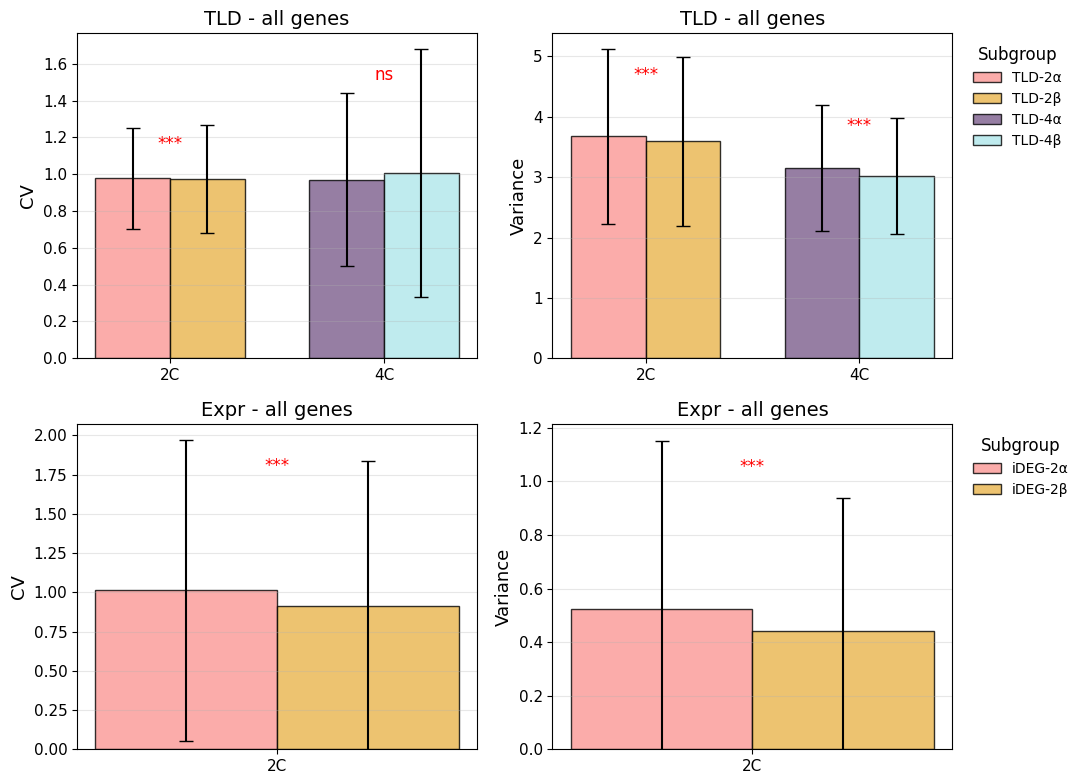

/home/lihaoxing/tmp/ipykernel_990627/1400035726.py:376: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/home/lihaoxing/tmp/ipykernel_990627/1400035726.py:376: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


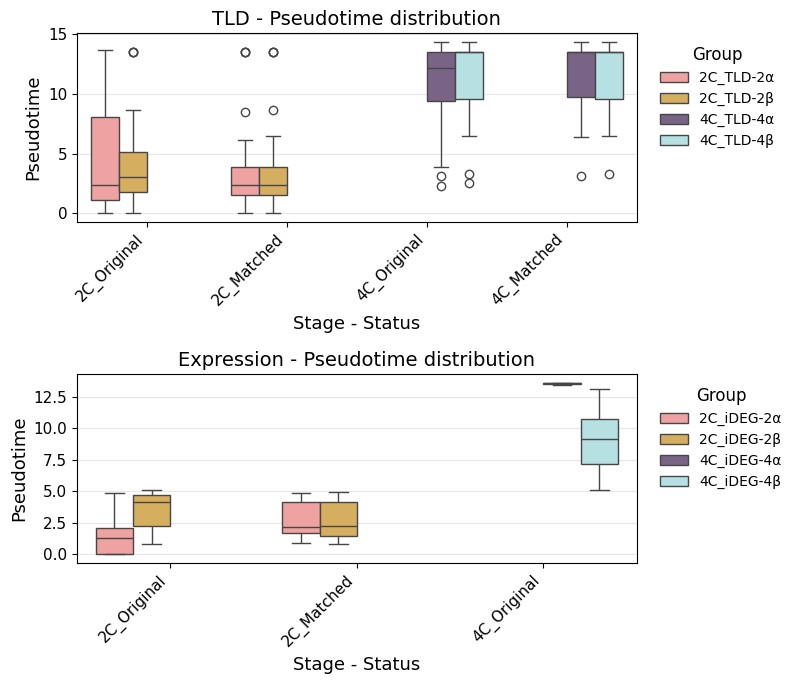


所有分析完成！
使用的匹配窗口宽度 = 0.5


In [6]:
#all genes
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
import seaborn as sns
import sys

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 13,
    'axes.titlesize': 14,
    'legend.fontsize': 10,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
})

# ---------- 可调参数 ----------
BIN_WIDTH_SAMPLE = 0.5
RANDOM_SEED = 42

# 每个 (data_type, stage) 的固定匹配种子，保证多次调用结果一致
STAGE_SEEDS = {
    ('tad',  '2C'): RANDOM_SEED + 1,
    ('tad',  '4C'): RANDOM_SEED + 2,
    ('expr', '2C'): RANDOM_SEED + 3,
    ('expr', '4C'): RANDOM_SEED + 4,
}

# ---------- 颜色映射（完整组名 -> 颜色） ----------
color_mapping_tad = {
    'TLD-2α':  '#fb9795',
    'TLD-2β':  '#E9B44C',
    'TLD-4α':  '#7c5e8c',
    'TLD-4β':  '#b0e7ea',
}
color_mapping_expr = {
    'iDEG-2α': '#fb9795',
    'iDEG-2β': '#E9B44C',
    'iDEG-4α': '#7c5e8c',
    'iDEG-4β': '#b0e7ea',
}

# ---------- 匹配缓存：(data_type, stage) -> (matched1, matched2) ----------
matched_cells_cache = {}

def time_match_sampling(cells1, cells2, time_dict, bin_width, seed=None):
    """按 pseudotime 分箱，逐箱在两组中各取 min(n1, n2) 个细胞。"""
    if not cells1 or not cells2:
        return [], []
    t1 = np.array([time_dict[c] for c in cells1 if c in time_dict])
    t2 = np.array([time_dict[c] for c in cells2 if c in time_dict])
    if len(t1) == 0 or len(t2) == 0:
        return [], []
    t_min, t_max = max(t1.min(), t2.min()), min(t1.max(), t2.max())
    if t_min >= t_max:
        return [], []

    bins = np.arange(t_min, t_max + bin_width, bin_width)
    rng = np.random.default_rng(seed) if seed is not None else np.random

    sampled1, sampled2 = [], []
    for i in range(len(bins) - 1):
        left, right = bins[i], bins[i + 1]
        in1 = [c for c in cells1 if left <= time_dict[c] < right]
        in2 = [c for c in cells2 if left <= time_dict[c] < right]
        n_keep = min(len(in1), len(in2))
        if n_keep > 0:
            if n_keep < len(in1):
                in1 = list(rng.choice(in1, n_keep, replace=False))
            if n_keep < len(in2):
                in2 = list(rng.choice(in2, n_keep, replace=False))
            sampled1.extend(in1)
            sampled2.extend(in2)
    return sampled1, sampled2

def get_matched(data_type, stage, h1_cells, h2_cells, time_dict):
    """带缓存的匹配；同一 (data_type, stage) 只算一次，统计/作图共用。"""
    key = (data_type, stage)
    if key not in matched_cells_cache:
        seed = STAGE_SEEDS.get(key, RANDOM_SEED)
        m1, m2 = time_match_sampling(h1_cells, h2_cells, time_dict,
                                     BIN_WIDTH_SAMPLE, seed=seed)
        matched_cells_cache[key] = (m1, m2)
    return matched_cells_cache[key]

# ====================================================================
# 0. 统计函数
# ====================================================================
def compute_stage_stats(exp_mat, gene_list, cells_h1, cells_h2, time_dict,
                        stage_name, h1_key, h2_key, data_type,
                        bin_width=BIN_WIDTH_SAMPLE):
    # ---- 原始（未匹配）统计 ----
    pt1_orig = [time_dict[c] for c in cells_h1 if c in time_dict]
    pt2_orig = [time_dict[c] for c in cells_h2 if c in time_dict]
    n1_orig, n2_orig = len(cells_h1), len(cells_h2)
    med1_orig = np.median(pt1_orig) if pt1_orig else np.nan
    min1_orig = np.min(pt1_orig)    if pt1_orig else np.nan
    max1_orig = np.max(pt1_orig)    if pt1_orig else np.nan
    med2_orig = np.median(pt2_orig) if pt2_orig else np.nan
    min2_orig = np.min(pt2_orig)    if pt2_orig else np.nan
    max2_orig = np.max(pt2_orig)    if pt2_orig else np.nan

    # ---- 时间匹配（缓存共用） ----
    matched1, matched2 = get_matched(data_type, stage_name,
                                     cells_h1, cells_h2, time_dict)
    n1_match, n2_match = len(matched1), len(matched2)

    if n1_match >= 2 and n2_match >= 2:
        pt1_match = [time_dict[c] for c in matched1]
        pt2_match = [time_dict[c] for c in matched2]
        med1_match, min1_match, max1_match = np.median(pt1_match), np.min(pt1_match), np.max(pt1_match)
        med2_match, min2_match, max2_match = np.median(pt2_match), np.min(pt2_match), np.max(pt2_match)
    else:
        med1_match = min1_match = max1_match = np.nan
        med2_match = min2_match = max2_match = np.nan

    print("\n" + "=" * 80)
    print(f"阶段: {stage_name}  (窗口宽度 = {bin_width})")
    print("=" * 80)
    print(f"{'亚群':<15}{'原始细胞数':<12}{'匹配后细胞数':<15}{'中位数[范围]':<30}")
    print("-" * 80)
    def fmt(med, mn, mx):
        return f"{med:.4f} [{mn:.4f},{mx:.4f}]" if not np.isnan(med) else "NA"
    print(f"{h1_key:<15}{n1_orig:<12}{n1_match:<15}{fmt(med1_orig, min1_orig, max1_orig)}")
    print(f"{h2_key:<15}{n2_orig:<12}{n2_match:<15}{fmt(med2_orig, min2_orig, max2_orig)}")
    print("\n匹配后时间分布：")
    print(f"{h1_key:<15}{n1_match:<12}{n1_match:<15}{fmt(med1_match, min1_match, max1_match)}")
    print(f"{h2_key:<15}{n2_match:<12}{n2_match:<15}{fmt(med2_match, min2_match, max2_match)}")
    print("=" * 80 + "\n")

    # ---- 计算 CV / Variance（基于匹配后的细胞） ----
    records = []
    if n1_match >= 2 and n2_match >= 2:
        for gene in gene_list:
            vals1 = exp_mat.loc[gene, matched1].values.astype(float)
            vals2 = exp_mat.loc[gene, matched2].values.astype(float)

            if len(vals1) >= 2:
                m1 = np.mean(vals1)
                cv1 = np.std(vals1, ddof=0) / m1 if m1 != 0 else np.nan
                records.append({'stage': stage_name, 'subgroup': h1_key,
                                'gene': gene, 'CV': cv1, 'Variance': np.var(vals1, ddof=0)})
            if len(vals2) >= 2:
                m2 = np.mean(vals2)
                cv2 = np.std(vals2, ddof=0) / m2 if m2 != 0 else np.nan
                records.append({'stage': stage_name, 'subgroup': h2_key,
                                'gene': gene, 'CV': cv2, 'Variance': np.var(vals2, ddof=0)})
    return pd.DataFrame(records)

# ====================================================================
# 1. 读数据
# ====================================================================
tad_file = "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_merged_tad_strength_matrix_new.txt"
tad_strength = pd.read_csv(tad_file, sep="\t", index_col=0).clip(lower=0)
tad_strength.columns = tad_strength.columns.str.strip()

expr_all = pd.read_csv("IVF_118cells_readcounts.txt", sep="\t", index_col=0)
expr_all.columns = expr_all.columns.str.strip()
total_reads = expr_all.sum(axis=0)
cpm = expr_all.div(total_reads / 1e6, axis=1)
expr_logcpm = np.log2(cpm + 1)

tad_time_df = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/ivf_time_sort.txt",
    sep="\t", header=None, names=['sample', 'pseudotime'],
)
tad_time_df['sample'] = tad_time_df['sample'].str.strip()
tad_time_dict = dict(zip(tad_time_df['sample'], tad_time_df['pseudotime']))

expr_time_df = pd.read_csv("IVF_scRNAseq_pseudotime_results_remove_gap.txt", sep="\t", header=0)
expr_time_df['cell_id'] = expr_time_df['cell_id'].str.strip()
expr_time_dict = dict(zip(expr_time_df['cell_id'], expr_time_df['pseudotime']))

tad_cells  = [c for c in tad_strength.columns  if c in tad_time_dict]
tad_strength = tad_strength[tad_cells]
expr_cells = [c for c in expr_logcpm.columns   if c in expr_time_dict]
expr_logcpm = expr_logcpm[expr_cells]

if len(tad_cells) == 0 or len(expr_cells) == 0:
    print("错误：细胞匹配为0，请检查ID格式。")
    sys.exit()

with open("/home/lihaoxing/scRNA_expression_vs_pseudotime/expressed_genes.txt") as f:
    zga_genes = [line.strip() for line in f if line.strip()]

tad_genes  = [g for g in zga_genes if g in tad_strength.index]
expr_genes = [g for g in zga_genes if g in expr_logcpm.index]
if expr_genes:
    avg_expr = expr_logcpm.loc[expr_genes].mean(axis=1)
    expr_genes = [g for g in expr_genes if avg_expr[g] > 0]

def read_ids(f):
    with open(f) as fp:
        return [line.strip() for line in fp if line.strip()]

tad_subgroups = {
    'TLD-2α': [c for c in read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C1_ID.txt") if c in tad_cells],
    'TLD-2β': [c for c in read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C2_ID.txt") if c in tad_cells],
    'TLD-4α': [c for c in read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D1_ID.txt") if c in tad_cells],
    'TLD-4β': [c for c in read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D2_ID.txt") if c in tad_cells],
}
expr_subgroups = {
    'iDEG-2α': [c for c in read_ids("IVF-2C-iDEG1.txt") if c in expr_cells],
    'iDEG-2β': [c for c in read_ids("IVF-2C-iDEG2.txt") if c in expr_cells],
    'iDEG-4α': [c for c in read_ids("IVF-4C-iDEG1.txt") if c in expr_cells],
    'iDEG-4β': [c for c in read_ids("IVF-4C-iDEG2.txt") if c in expr_cells],
}

stage_pairs_tad  = {'2C': ('TLD-2α',  'TLD-2β'),
                    '4C': ('TLD-4α',  'TLD-4β')}
stage_pairs_expr = {'2C': ('iDEG-2α', 'iDEG-2β'),
                    '4C': ('iDEG-4α', 'iDEG-4β')}

# ====================================================================
# 2. 计算统计量
# ====================================================================
all_results_tad, all_results_expr = [], []

for stage, (h1_key, h2_key) in stage_pairs_tad.items():
    all_results_tad.append(compute_stage_stats(
        exp_mat=tad_strength, gene_list=tad_genes,
        cells_h1=tad_subgroups[h1_key], cells_h2=tad_subgroups[h2_key],
        time_dict=tad_time_dict,
        stage_name=stage, h1_key=h1_key, h2_key=h2_key,
        data_type='tad', bin_width=BIN_WIDTH_SAMPLE,
    ))

for stage, (h1_key, h2_key) in stage_pairs_expr.items():
    all_results_expr.append(compute_stage_stats(
        exp_mat=expr_logcpm, gene_list=expr_genes,
        cells_h1=expr_subgroups[h1_key], cells_h2=expr_subgroups[h2_key],
        time_dict=expr_time_dict,
        stage_name=stage, h1_key=h1_key, h2_key=h2_key,
        data_type='expr', bin_width=BIN_WIDTH_SAMPLE,
    ))

df_tad_all  = pd.concat(all_results_tad,  ignore_index=True)
df_expr_all = pd.concat(all_results_expr, ignore_index=True)

# ====================================================================
# 3. 柱状图 + 显著性
# ====================================================================
def plot_bar_with_stats(ax, df, y_col, ylabel, title, color_map, show_legend=True):
    stats_df = df.groupby(['stage', 'subgroup'])[y_col] \
                 .agg(['mean', 'std', 'count']).reset_index()
    stats_df.columns = ['stage', 'subgroup', 'mean', 'std', 'n']
    stats_df = stats_df.dropna(subset=['mean'])

    stages = sorted(stats_df['stage'].unique(), key=lambda x: (x != '2C', x))
    x = np.arange(len(stages))
    width = 0.35

    for i, stage in enumerate(stages):
        sub_data = stats_df[stats_df['stage'] == stage]
        subgroups = sorted(sub_data['subgroup'].tolist())
        for j, sub in enumerate(subgroups):
            row = sub_data[sub_data['subgroup'] == sub].iloc[0]
            pos = x[i] + (j - 0.5) * width
            ax.bar(pos, row['mean'], width,
                   yerr=row['std'], capsize=5,
                   color=color_map.get(sub, 'gray'), alpha=0.8,
                   edgecolor='black',
                   label=sub if show_legend else "")

    ax.set_xticks(x)
    ax.set_xticklabels(stages)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(axis='y', alpha=0.3)
    ax.set_ylim(bottom=0)

    if show_legend:
        handles, labels_ = ax.get_legend_handles_labels()
        by_label = dict(zip(labels_, handles))
        ax.legend(by_label.values(), by_label.keys(), title='Subgroup',
                  loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)

    # 显著性检验（同 stage 两亚群之间）
    for idx, stage in enumerate(stages):
        sub_data = stats_df[stats_df['stage'] == stage]
        if len(sub_data) != 2:
            continue
        sub1, sub2 = sub_data.iloc[0]['subgroup'], sub_data.iloc[1]['subgroup']
        vals1 = df[(df['stage'] == stage) & (df['subgroup'] == sub1)][y_col].dropna()
        vals2 = df[(df['stage'] == stage) & (df['subgroup'] == sub2)][y_col].dropna()
        if len(vals1) > 1 and len(vals2) > 1:
            _, p = mannwhitneyu(vals1, vals2, alternative='two-sided')
            sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
            max_h = float((sub_data['mean'] + sub_data['std']).max())
            y_pos = max_h * 0.9 if max_h > 0 else 0.1
            ax.text(idx, y_pos, sig, ha='center', fontsize=12, color='red')

# ====================================================================
# 4. 主图
# ====================================================================
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

plot_bar_with_stats(axes[0, 0], df_tad_all,  'CV',       'CV',
                    'TLD - all genes',  color_mapping_tad,  show_legend=False)
plot_bar_with_stats(axes[0, 1], df_tad_all,  'Variance', 'Variance',
                    'TLD - all genes',  color_mapping_tad,  show_legend=True)

plot_bar_with_stats(axes[1, 0], df_expr_all, 'CV',       'CV',
                    'Expr - all genes', color_mapping_expr, show_legend=False)
plot_bar_with_stats(axes[1, 1], df_expr_all, 'Variance', 'Variance',
                    'Expr - all genes', color_mapping_expr, show_legend=True)

plt.tight_layout()
plt.savefig('IVF_CV_Variance_all.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# ====================================================================
# 5. 时间分布图
# ====================================================================
def collect_time_data(subgroups_dict, time_dict, stage_pairs,
                      data_type, status='Original'):
    records = []
    for stage, (h1_key, h2_key) in stage_pairs.items():
        if status == 'Original':
            c1, c2 = subgroups_dict[h1_key], subgroups_dict[h2_key]
        else:
            c1, c2 = get_matched(data_type, stage,
                                 subgroups_dict[h1_key],
                                 subgroups_dict[h2_key],
                                 time_dict)
        for c in c1:
            records.append({'stage': stage, 'subgroup': h1_key,
                            'pseudotime': time_dict[c], 'status': status})
        for c in c2:
            records.append({'stage': stage, 'subgroup': h2_key,
                            'pseudotime': time_dict[c], 'status': status})
    return pd.DataFrame(records)

df_tad_time = pd.concat([
    collect_time_data(tad_subgroups, tad_time_dict, stage_pairs_tad,  'tad',  'Original'),
    collect_time_data(tad_subgroups, tad_time_dict, stage_pairs_tad,  'tad',  'Matched'),
], ignore_index=True)

df_expr_time = pd.concat([
    collect_time_data(expr_subgroups, expr_time_dict, stage_pairs_expr, 'expr', 'Original'),
    collect_time_data(expr_subgroups, expr_time_dict, stage_pairs_expr, 'expr', 'Matched'),
], ignore_index=True)

df_tad_time['group']  = df_tad_time['stage']  + '_' + df_tad_time['subgroup']
df_expr_time['group'] = df_expr_time['stage'] + '_' + df_expr_time['subgroup']

def plot_time_distribution(ax, df, data_type, color_map, stage_pairs):
    df_plot = df.copy()
    df_plot['stage_status'] = df_plot['stage'] + '_' + df_plot['status']
    order = ['2C_Original', '2C_Matched', '4C_Original', '4C_Matched']
    available = [o for o in order if o in df_plot['stage_status'].unique()]

    # 构造 group -> 颜色的映射（修复原 palette 键不匹配问题）
    group_palette = {}
    hue_order = []
    for stage, (h1, h2) in stage_pairs.items():
        for h in (h1, h2):
            key = f'{stage}_{h}'
            group_palette[key] = color_map.get(h, 'gray')
            hue_order.append(key)
    hue_order = [h for h in hue_order if h in df_plot['group'].unique()]

    sns.boxplot(x='stage_status', y='pseudotime', hue='group', data=df_plot,
                order=available, hue_order=hue_order,
                palette=group_palette, dodge=True, ax=ax)
    ax.set_xlabel('Stage - Status')
    ax.set_ylabel('Pseudotime')
    ax.set_title(f'{data_type} - Pseudotime distribution')
    ax.legend(title='Group', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
    ax.grid(axis='y', alpha=0.3)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 7))
plot_time_distribution(ax1, df_tad_time,  'TLD',        color_mapping_tad,  stage_pairs_tad)
plot_time_distribution(ax2, df_expr_time, 'Expression', color_mapping_expr, stage_pairs_expr)
plt.tight_layout()
plt.savefig('IVF_CV_Variance_all_TimeDistribution.svg',
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

print("\n所有分析完成！")
print(f"使用的匹配窗口宽度 = {BIN_WIDTH_SAMPLE}")


阶段: 2C  (窗口宽度 = 0.5)
亚群             原始细胞数       匹配后细胞数         中位数[范围]                       
--------------------------------------------------------------------------------
TLD-2α         62          24             2.3560 [0.0000,13.6627]
TLD-2β         31          24             3.0506 [0.0000,13.5564]

匹配后时间分布：
TLD-2α         24          24             2.3560 [0.0000,13.5564]
TLD-2β         24          24             2.3865 [0.0001,13.5564]


阶段: 4C  (窗口宽度 = 0.5)
亚群             原始细胞数       匹配后细胞数         中位数[范围]                       
--------------------------------------------------------------------------------
TLD-4α         131         57             12.2115 [2.2713,14.3694]
TLD-4β         60          57             13.5565 [2.5810,14.3736]

匹配后时间分布：
TLD-4α         57          57             13.5565 [3.1409,14.3694]
TLD-4β         57          57             13.5565 [3.2973,14.3736]


阶段: 2C  (窗口宽度 = 0.5)
亚群             原始细胞数       匹配后细胞数         中位数[范围]                       

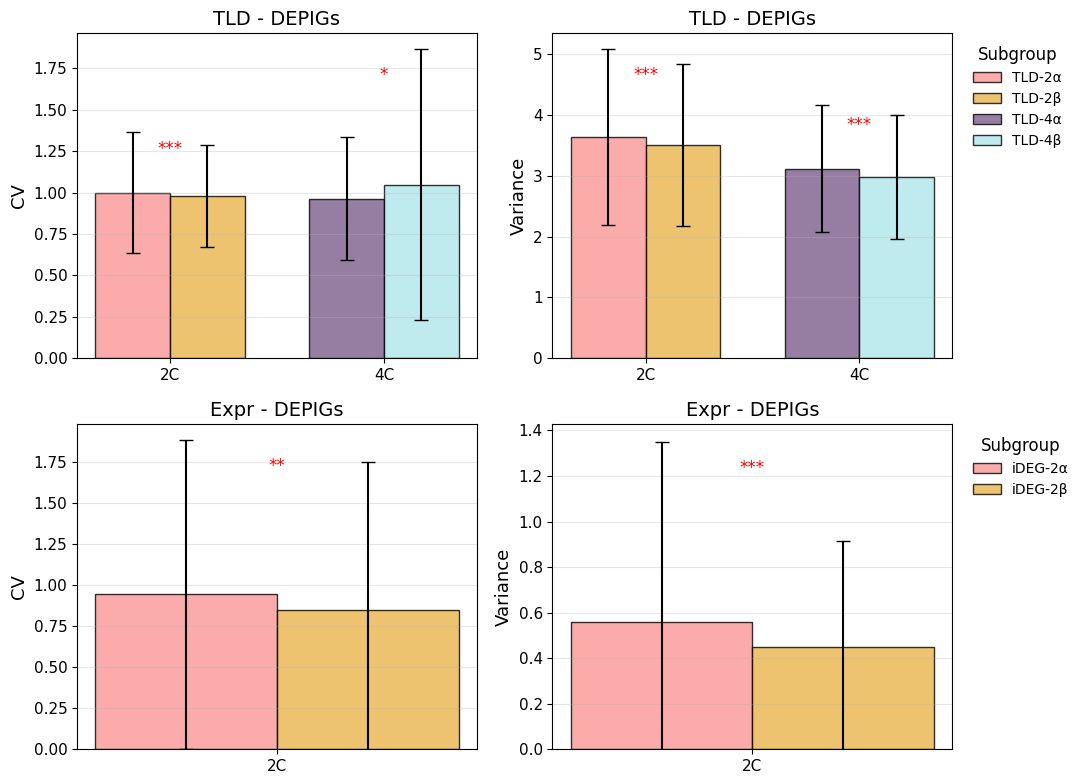

/home/lihaoxing/tmp/ipykernel_990627/1487358979.py:376: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/home/lihaoxing/tmp/ipykernel_990627/1487358979.py:376: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


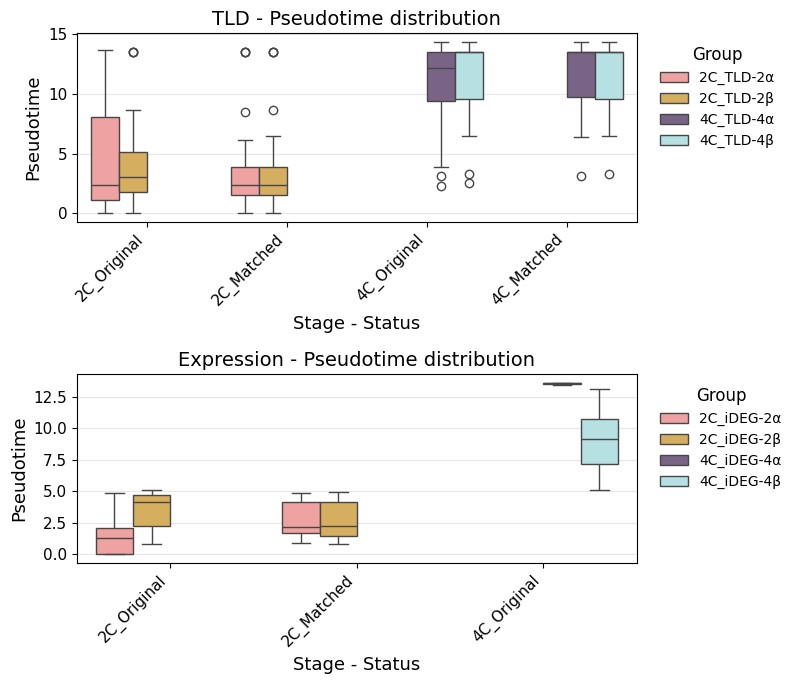


所有分析完成！
使用的匹配窗口宽度 = 0.5


In [11]:
#deboundary genes
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
import seaborn as sns
import sys

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 13,
    'axes.titlesize': 14,
    'legend.fontsize': 10,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
})

# ---------- 可调参数 ----------
BIN_WIDTH_SAMPLE = 0.5
RANDOM_SEED = 42

# 每个 (data_type, stage) 的固定匹配种子，保证多次调用结果一致
STAGE_SEEDS = {
    ('tad',  '2C'): RANDOM_SEED + 1,
    ('tad',  '4C'): RANDOM_SEED + 2,
    ('expr', '2C'): RANDOM_SEED + 3,
    ('expr', '4C'): RANDOM_SEED + 4,
}

# ---------- 颜色映射（完整组名 -> 颜色） ----------
color_mapping_tad = {
    'TLD-2α':  '#fb9795',
    'TLD-2β':  '#E9B44C',
    'TLD-4α':  '#7c5e8c',
    'TLD-4β':  '#b0e7ea',
}
color_mapping_expr = {
    'iDEG-2α': '#fb9795',
    'iDEG-2β': '#E9B44C',
    'iDEG-4α': '#7c5e8c',
    'iDEG-4β': '#b0e7ea',
}

# ---------- 匹配缓存：(data_type, stage) -> (matched1, matched2) ----------
matched_cells_cache = {}

def time_match_sampling(cells1, cells2, time_dict, bin_width, seed=None):
    """按 pseudotime 分箱，逐箱在两组中各取 min(n1, n2) 个细胞。"""
    if not cells1 or not cells2:
        return [], []
    t1 = np.array([time_dict[c] for c in cells1 if c in time_dict])
    t2 = np.array([time_dict[c] for c in cells2 if c in time_dict])
    if len(t1) == 0 or len(t2) == 0:
        return [], []
    t_min, t_max = max(t1.min(), t2.min()), min(t1.max(), t2.max())
    if t_min >= t_max:
        return [], []

    bins = np.arange(t_min, t_max + bin_width, bin_width)
    rng = np.random.default_rng(seed) if seed is not None else np.random

    sampled1, sampled2 = [], []
    for i in range(len(bins) - 1):
        left, right = bins[i], bins[i + 1]
        in1 = [c for c in cells1 if left <= time_dict[c] < right]
        in2 = [c for c in cells2 if left <= time_dict[c] < right]
        n_keep = min(len(in1), len(in2))
        if n_keep > 0:
            if n_keep < len(in1):
                in1 = list(rng.choice(in1, n_keep, replace=False))
            if n_keep < len(in2):
                in2 = list(rng.choice(in2, n_keep, replace=False))
            sampled1.extend(in1)
            sampled2.extend(in2)
    return sampled1, sampled2

def get_matched(data_type, stage, h1_cells, h2_cells, time_dict):
    """带缓存的匹配；同一 (data_type, stage) 只算一次，统计/作图共用。"""
    key = (data_type, stage)
    if key not in matched_cells_cache:
        seed = STAGE_SEEDS.get(key, RANDOM_SEED)
        m1, m2 = time_match_sampling(h1_cells, h2_cells, time_dict,
                                     BIN_WIDTH_SAMPLE, seed=seed)
        matched_cells_cache[key] = (m1, m2)
    return matched_cells_cache[key]

# ====================================================================
# 0. 统计函数
# ====================================================================
def compute_stage_stats(exp_mat, gene_list, cells_h1, cells_h2, time_dict,
                        stage_name, h1_key, h2_key, data_type,
                        bin_width=BIN_WIDTH_SAMPLE):
    # ---- 原始（未匹配）统计 ----
    pt1_orig = [time_dict[c] for c in cells_h1 if c in time_dict]
    pt2_orig = [time_dict[c] for c in cells_h2 if c in time_dict]
    n1_orig, n2_orig = len(cells_h1), len(cells_h2)
    med1_orig = np.median(pt1_orig) if pt1_orig else np.nan
    min1_orig = np.min(pt1_orig)    if pt1_orig else np.nan
    max1_orig = np.max(pt1_orig)    if pt1_orig else np.nan
    med2_orig = np.median(pt2_orig) if pt2_orig else np.nan
    min2_orig = np.min(pt2_orig)    if pt2_orig else np.nan
    max2_orig = np.max(pt2_orig)    if pt2_orig else np.nan

    # ---- 时间匹配（缓存共用） ----
    matched1, matched2 = get_matched(data_type, stage_name,
                                     cells_h1, cells_h2, time_dict)
    n1_match, n2_match = len(matched1), len(matched2)

    if n1_match >= 2 and n2_match >= 2:
        pt1_match = [time_dict[c] for c in matched1]
        pt2_match = [time_dict[c] for c in matched2]
        med1_match, min1_match, max1_match = np.median(pt1_match), np.min(pt1_match), np.max(pt1_match)
        med2_match, min2_match, max2_match = np.median(pt2_match), np.min(pt2_match), np.max(pt2_match)
    else:
        med1_match = min1_match = max1_match = np.nan
        med2_match = min2_match = max2_match = np.nan

    print("\n" + "=" * 80)
    print(f"阶段: {stage_name}  (窗口宽度 = {bin_width})")
    print("=" * 80)
    print(f"{'亚群':<15}{'原始细胞数':<12}{'匹配后细胞数':<15}{'中位数[范围]':<30}")
    print("-" * 80)
    def fmt(med, mn, mx):
        return f"{med:.4f} [{mn:.4f},{mx:.4f}]" if not np.isnan(med) else "NA"
    print(f"{h1_key:<15}{n1_orig:<12}{n1_match:<15}{fmt(med1_orig, min1_orig, max1_orig)}")
    print(f"{h2_key:<15}{n2_orig:<12}{n2_match:<15}{fmt(med2_orig, min2_orig, max2_orig)}")
    print("\n匹配后时间分布：")
    print(f"{h1_key:<15}{n1_match:<12}{n1_match:<15}{fmt(med1_match, min1_match, max1_match)}")
    print(f"{h2_key:<15}{n2_match:<12}{n2_match:<15}{fmt(med2_match, min2_match, max2_match)}")
    print("=" * 80 + "\n")

    # ---- 计算 CV / Variance（基于匹配后的细胞） ----
    records = []
    if n1_match >= 2 and n2_match >= 2:
        for gene in gene_list:
            vals1 = exp_mat.loc[gene, matched1].values.astype(float)
            vals2 = exp_mat.loc[gene, matched2].values.astype(float)

            if len(vals1) >= 2:
                m1 = np.mean(vals1)
                cv1 = np.std(vals1, ddof=0) / m1 if m1 != 0 else np.nan
                records.append({'stage': stage_name, 'subgroup': h1_key,
                                'gene': gene, 'CV': cv1, 'Variance': np.var(vals1, ddof=0)})
            if len(vals2) >= 2:
                m2 = np.mean(vals2)
                cv2 = np.std(vals2, ddof=0) / m2 if m2 != 0 else np.nan
                records.append({'stage': stage_name, 'subgroup': h2_key,
                                'gene': gene, 'CV': cv2, 'Variance': np.var(vals2, ddof=0)})
    return pd.DataFrame(records)

# ====================================================================
# 1. 读数据
# ====================================================================
tad_file = "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_merged_tad_strength_matrix_new.txt"
tad_strength = pd.read_csv(tad_file, sep="\t", index_col=0).clip(lower=0)
tad_strength.columns = tad_strength.columns.str.strip()

expr_all = pd.read_csv("IVF_118cells_readcounts.txt", sep="\t", index_col=0)
expr_all.columns = expr_all.columns.str.strip()
total_reads = expr_all.sum(axis=0)
cpm = expr_all.div(total_reads / 1e6, axis=1)
expr_logcpm = np.log2(cpm + 1)

tad_time_df = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/ivf_time_sort.txt",
    sep="\t", header=None, names=['sample', 'pseudotime'],
)
tad_time_df['sample'] = tad_time_df['sample'].str.strip()
tad_time_dict = dict(zip(tad_time_df['sample'], tad_time_df['pseudotime']))

expr_time_df = pd.read_csv("IVF_scRNAseq_pseudotime_results_remove_gap.txt", sep="\t", header=0)
expr_time_df['cell_id'] = expr_time_df['cell_id'].str.strip()
expr_time_dict = dict(zip(expr_time_df['cell_id'], expr_time_df['pseudotime']))

tad_cells  = [c for c in tad_strength.columns  if c in tad_time_dict]
tad_strength = tad_strength[tad_cells]
expr_cells = [c for c in expr_logcpm.columns   if c in expr_time_dict]
expr_logcpm = expr_logcpm[expr_cells]

if len(tad_cells) == 0 or len(expr_cells) == 0:
    print("错误：细胞匹配为0，请检查ID格式。")
    sys.exit()

with open("/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_morula_boundaries_80k_2C_4C_deboundary2gene_id.txt") as f:
    zga_genes = [line.strip() for line in f if line.strip()]

tad_genes  = [g for g in zga_genes if g in tad_strength.index]
expr_genes = [g for g in zga_genes if g in expr_logcpm.index]
if expr_genes:
    avg_expr = expr_logcpm.loc[expr_genes].mean(axis=1)
    expr_genes = [g for g in expr_genes if avg_expr[g] > 0]

def read_ids(f):
    with open(f) as fp:
        return [line.strip() for line in fp if line.strip()]

tad_subgroups = {
    'TLD-2α': [c for c in read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C1_ID.txt") if c in tad_cells],
    'TLD-2β': [c for c in read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C2_ID.txt") if c in tad_cells],
    'TLD-4α': [c for c in read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D1_ID.txt") if c in tad_cells],
    'TLD-4β': [c for c in read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D2_ID.txt") if c in tad_cells],
}
expr_subgroups = {
    'iDEG-2α': [c for c in read_ids("IVF-2C-iDEG1.txt") if c in expr_cells],
    'iDEG-2β': [c for c in read_ids("IVF-2C-iDEG2.txt") if c in expr_cells],
    'iDEG-4α': [c for c in read_ids("IVF-4C-iDEG1.txt") if c in expr_cells],
    'iDEG-4β': [c for c in read_ids("IVF-4C-iDEG2.txt") if c in expr_cells],
}

stage_pairs_tad  = {'2C': ('TLD-2α',  'TLD-2β'),
                    '4C': ('TLD-4α',  'TLD-4β')}
stage_pairs_expr = {'2C': ('iDEG-2α', 'iDEG-2β'),
                    '4C': ('iDEG-4α', 'iDEG-4β')}

# ====================================================================
# 2. 计算统计量
# ====================================================================
all_results_tad, all_results_expr = [], []

for stage, (h1_key, h2_key) in stage_pairs_tad.items():
    all_results_tad.append(compute_stage_stats(
        exp_mat=tad_strength, gene_list=tad_genes,
        cells_h1=tad_subgroups[h1_key], cells_h2=tad_subgroups[h2_key],
        time_dict=tad_time_dict,
        stage_name=stage, h1_key=h1_key, h2_key=h2_key,
        data_type='tad', bin_width=BIN_WIDTH_SAMPLE,
    ))

for stage, (h1_key, h2_key) in stage_pairs_expr.items():
    all_results_expr.append(compute_stage_stats(
        exp_mat=expr_logcpm, gene_list=expr_genes,
        cells_h1=expr_subgroups[h1_key], cells_h2=expr_subgroups[h2_key],
        time_dict=expr_time_dict,
        stage_name=stage, h1_key=h1_key, h2_key=h2_key,
        data_type='expr', bin_width=BIN_WIDTH_SAMPLE,
    ))

df_tad_all  = pd.concat(all_results_tad,  ignore_index=True)
df_expr_all = pd.concat(all_results_expr, ignore_index=True)

# ====================================================================
# 3. 柱状图 + 显著性
# ====================================================================
def plot_bar_with_stats(ax, df, y_col, ylabel, title, color_map, show_legend=True):
    stats_df = df.groupby(['stage', 'subgroup'])[y_col] \
                 .agg(['mean', 'std', 'count']).reset_index()
    stats_df.columns = ['stage', 'subgroup', 'mean', 'std', 'n']
    stats_df = stats_df.dropna(subset=['mean'])

    stages = sorted(stats_df['stage'].unique(), key=lambda x: (x != '2C', x))
    x = np.arange(len(stages))
    width = 0.35

    for i, stage in enumerate(stages):
        sub_data = stats_df[stats_df['stage'] == stage]
        subgroups = sorted(sub_data['subgroup'].tolist())
        for j, sub in enumerate(subgroups):
            row = sub_data[sub_data['subgroup'] == sub].iloc[0]
            pos = x[i] + (j - 0.5) * width
            ax.bar(pos, row['mean'], width,
                   yerr=row['std'], capsize=5,
                   color=color_map.get(sub, 'gray'), alpha=0.8,
                   edgecolor='black',
                   label=sub if show_legend else "")

    ax.set_xticks(x)
    ax.set_xticklabels(stages)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(axis='y', alpha=0.3)
    ax.set_ylim(bottom=0)

    if show_legend:
        handles, labels_ = ax.get_legend_handles_labels()
        by_label = dict(zip(labels_, handles))
        ax.legend(by_label.values(), by_label.keys(), title='Subgroup',
                  loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)

    # 显著性检验（同 stage 两亚群之间）
    for idx, stage in enumerate(stages):
        sub_data = stats_df[stats_df['stage'] == stage]
        if len(sub_data) != 2:
            continue
        sub1, sub2 = sub_data.iloc[0]['subgroup'], sub_data.iloc[1]['subgroup']
        vals1 = df[(df['stage'] == stage) & (df['subgroup'] == sub1)][y_col].dropna()
        vals2 = df[(df['stage'] == stage) & (df['subgroup'] == sub2)][y_col].dropna()
        if len(vals1) > 1 and len(vals2) > 1:
            _, p = mannwhitneyu(vals1, vals2, alternative='two-sided')
            sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
            max_h = float((sub_data['mean'] + sub_data['std']).max())
            y_pos = max_h * 0.9 if max_h > 0 else 0.1
            ax.text(idx, y_pos, sig, ha='center', fontsize=12, color='red')

# ====================================================================
# 4. 主图
# ====================================================================
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

plot_bar_with_stats(axes[0, 0], df_tad_all,  'CV',       'CV',
                    'TLD - DEPIGs',  color_mapping_tad,  show_legend=False)
plot_bar_with_stats(axes[0, 1], df_tad_all,  'Variance', 'Variance',
                    'TLD - DEPIGs',  color_mapping_tad,  show_legend=True)

plot_bar_with_stats(axes[1, 0], df_expr_all, 'CV',       'CV',
                    'Expr - DEPIGs', color_mapping_expr, show_legend=False)
plot_bar_with_stats(axes[1, 1], df_expr_all, 'Variance', 'Variance',
                    'Expr - DEPIGs', color_mapping_expr, show_legend=True)

plt.tight_layout()
plt.savefig('IVF_CV_Variance_DEPIGs.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# ====================================================================
# 5. 时间分布图
# ====================================================================
def collect_time_data(subgroups_dict, time_dict, stage_pairs,
                      data_type, status='Original'):
    records = []
    for stage, (h1_key, h2_key) in stage_pairs.items():
        if status == 'Original':
            c1, c2 = subgroups_dict[h1_key], subgroups_dict[h2_key]
        else:
            c1, c2 = get_matched(data_type, stage,
                                 subgroups_dict[h1_key],
                                 subgroups_dict[h2_key],
                                 time_dict)
        for c in c1:
            records.append({'stage': stage, 'subgroup': h1_key,
                            'pseudotime': time_dict[c], 'status': status})
        for c in c2:
            records.append({'stage': stage, 'subgroup': h2_key,
                            'pseudotime': time_dict[c], 'status': status})
    return pd.DataFrame(records)

df_tad_time = pd.concat([
    collect_time_data(tad_subgroups, tad_time_dict, stage_pairs_tad,  'tad',  'Original'),
    collect_time_data(tad_subgroups, tad_time_dict, stage_pairs_tad,  'tad',  'Matched'),
], ignore_index=True)

df_expr_time = pd.concat([
    collect_time_data(expr_subgroups, expr_time_dict, stage_pairs_expr, 'expr', 'Original'),
    collect_time_data(expr_subgroups, expr_time_dict, stage_pairs_expr, 'expr', 'Matched'),
], ignore_index=True)

df_tad_time['group']  = df_tad_time['stage']  + '_' + df_tad_time['subgroup']
df_expr_time['group'] = df_expr_time['stage'] + '_' + df_expr_time['subgroup']

def plot_time_distribution(ax, df, data_type, color_map, stage_pairs):
    df_plot = df.copy()
    df_plot['stage_status'] = df_plot['stage'] + '_' + df_plot['status']
    order = ['2C_Original', '2C_Matched', '4C_Original', '4C_Matched']
    available = [o for o in order if o in df_plot['stage_status'].unique()]

    # 构造 group -> 颜色的映射（修复原 palette 键不匹配问题）
    group_palette = {}
    hue_order = []
    for stage, (h1, h2) in stage_pairs.items():
        for h in (h1, h2):
            key = f'{stage}_{h}'
            group_palette[key] = color_map.get(h, 'gray')
            hue_order.append(key)
    hue_order = [h for h in hue_order if h in df_plot['group'].unique()]

    sns.boxplot(x='stage_status', y='pseudotime', hue='group', data=df_plot,
                order=available, hue_order=hue_order,
                palette=group_palette, dodge=True, ax=ax)
    ax.set_xlabel('Stage - Status')
    ax.set_ylabel('Pseudotime')
    ax.set_title(f'{data_type} - Pseudotime distribution')
    ax.legend(title='Group', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
    ax.grid(axis='y', alpha=0.3)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 7))
plot_time_distribution(ax1, df_tad_time,  'TLD',        color_mapping_tad,  stage_pairs_tad)
plot_time_distribution(ax2, df_expr_time, 'Expression', color_mapping_expr, stage_pairs_expr)
plt.tight_layout()
plt.savefig('IVF_CV_Variance_deboundary_TimeDistribution.svg',
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

print("\n所有分析完成！")
print(f"使用的匹配窗口宽度 = {BIN_WIDTH_SAMPLE}")


阶段: 2C  (窗口宽度 = 0.5)
亚群             原始细胞数       匹配后细胞数         中位数[范围]                       
--------------------------------------------------------------------------------
TLD-2α         62          24             2.3560 [0.0000,13.6627]
TLD-2β         31          24             3.0506 [0.0000,13.5564]

匹配后时间分布：
TLD-2α         24          24             2.3560 [0.0000,13.5564]
TLD-2β         24          24             2.3865 [0.0001,13.5564]


阶段: 4C  (窗口宽度 = 0.5)
亚群             原始细胞数       匹配后细胞数         中位数[范围]                       
--------------------------------------------------------------------------------
TLD-4α         131         57             12.2115 [2.2713,14.3694]
TLD-4β         60          57             13.5565 [2.5810,14.3736]

匹配后时间分布：
TLD-4α         57          57             13.5565 [3.1409,14.3694]
TLD-4β         57          57             13.5565 [3.2973,14.3736]


阶段: 2C  (窗口宽度 = 0.5)
亚群             原始细胞数       匹配后细胞数         中位数[范围]                       

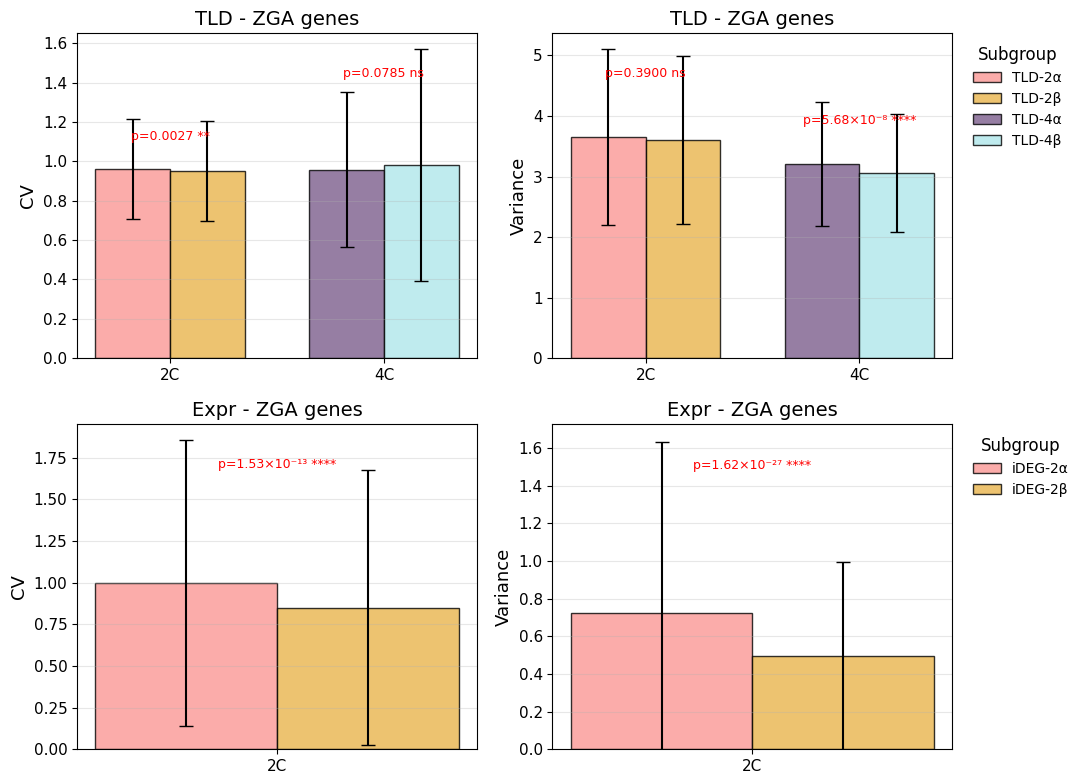

/home/lihaoxing/tmp/ipykernel_990627/2857800054.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/home/lihaoxing/tmp/ipykernel_990627/2857800054.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


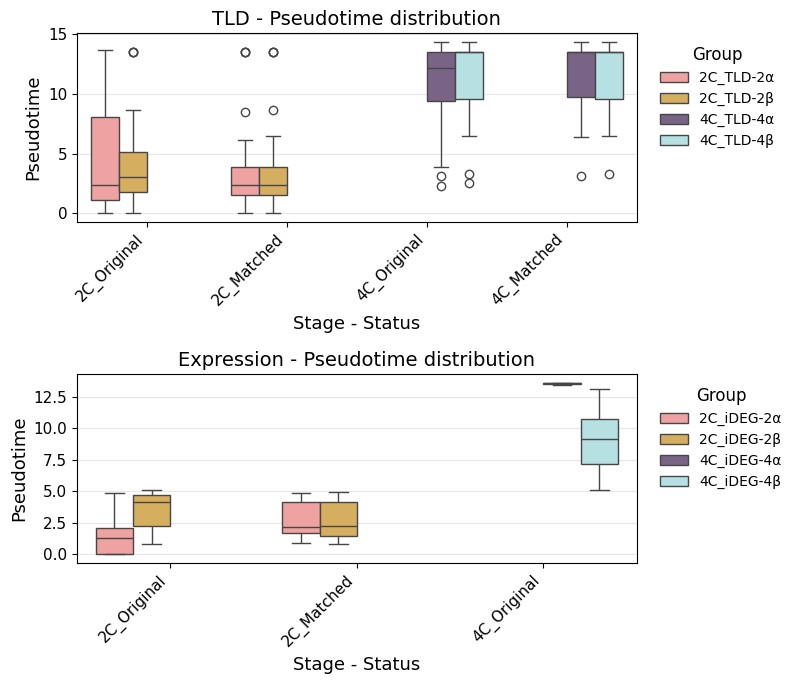


所有分析完成！
使用的匹配窗口宽度 = 0.5


In [12]:
#只看ZGA id
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
import seaborn as sns
import sys

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 13,
    'axes.titlesize': 14,
    'legend.fontsize': 10,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
})

# ---------- 可调参数 ----------
BIN_WIDTH_SAMPLE = 0.5
RANDOM_SEED = 42

ALPHA = 0.05

SUP_MAP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

def format_p_value(p):
    """p 值不用 e 表示：>=0.001 用小数，<0.001 用 ×10⁻ⁿ。"""
    if p is None or np.isnan(p):
        return "p=NA"
    if p <= 0:
        return "p<1×10⁻³⁰⁰"
    if p >= 0.001:
        return f"p={p:.4f}"
    exp = int(np.floor(np.log10(p)))
    mant = p / (10 ** exp)
    exp_str = str(exp).translate(SUP_MAP)
    return f"p={mant:.2f}×10{exp_str}"

def get_p_annotation(p):
    if p is None or np.isnan(p):
        return "ns"
    if p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < ALPHA:
        return "*"
    else:
        return "ns"
    
# 每个 (data_type, stage) 的固定匹配种子，保证多次调用结果一致
STAGE_SEEDS = {
    ('tad',  '2C'): RANDOM_SEED + 1,
    ('tad',  '4C'): RANDOM_SEED + 2,
    ('expr', '2C'): RANDOM_SEED + 3,
    ('expr', '4C'): RANDOM_SEED + 4,
}

# ---------- 颜色映射（完整组名 -> 颜色） ----------
color_mapping_tad = {
    'TLD-2α':  '#fb9795',
    'TLD-2β':  '#E9B44C',
    'TLD-4α':  '#7c5e8c',
    'TLD-4β':  '#b0e7ea',
}
color_mapping_expr = {
    'iDEG-2α': '#fb9795',
    'iDEG-2β': '#E9B44C',
    'iDEG-4α': '#7c5e8c',
    'iDEG-4β': '#b0e7ea',
}

# ---------- 匹配缓存：(data_type, stage) -> (matched1, matched2) ----------
matched_cells_cache = {}

def time_match_sampling(cells1, cells2, time_dict, bin_width, seed=None):
    """按 pseudotime 分箱，逐箱在两组中各取 min(n1, n2) 个细胞。"""
    if not cells1 or not cells2:
        return [], []
    t1 = np.array([time_dict[c] for c in cells1 if c in time_dict])
    t2 = np.array([time_dict[c] for c in cells2 if c in time_dict])
    if len(t1) == 0 or len(t2) == 0:
        return [], []
    t_min, t_max = max(t1.min(), t2.min()), min(t1.max(), t2.max())
    if t_min >= t_max:
        return [], []

    bins = np.arange(t_min, t_max + bin_width, bin_width)
    rng = np.random.default_rng(seed) if seed is not None else np.random

    sampled1, sampled2 = [], []
    for i in range(len(bins) - 1):
        left, right = bins[i], bins[i + 1]
        in1 = [c for c in cells1 if left <= time_dict[c] < right]
        in2 = [c for c in cells2 if left <= time_dict[c] < right]
        n_keep = min(len(in1), len(in2))
        if n_keep > 0:
            if n_keep < len(in1):
                in1 = list(rng.choice(in1, n_keep, replace=False))
            if n_keep < len(in2):
                in2 = list(rng.choice(in2, n_keep, replace=False))
            sampled1.extend(in1)
            sampled2.extend(in2)
    return sampled1, sampled2

def get_matched(data_type, stage, h1_cells, h2_cells, time_dict):
    """带缓存的匹配；同一 (data_type, stage) 只算一次，统计/作图共用。"""
    key = (data_type, stage)
    if key not in matched_cells_cache:
        seed = STAGE_SEEDS.get(key, RANDOM_SEED)
        m1, m2 = time_match_sampling(h1_cells, h2_cells, time_dict,
                                     BIN_WIDTH_SAMPLE, seed=seed)
        matched_cells_cache[key] = (m1, m2)
    return matched_cells_cache[key]

# ====================================================================
# 0. 统计函数
# ====================================================================
def compute_stage_stats(exp_mat, gene_list, cells_h1, cells_h2, time_dict,
                        stage_name, h1_key, h2_key, data_type,
                        bin_width=BIN_WIDTH_SAMPLE):
    # ---- 原始（未匹配）统计 ----
    pt1_orig = [time_dict[c] for c in cells_h1 if c in time_dict]
    pt2_orig = [time_dict[c] for c in cells_h2 if c in time_dict]
    n1_orig, n2_orig = len(cells_h1), len(cells_h2)
    med1_orig = np.median(pt1_orig) if pt1_orig else np.nan
    min1_orig = np.min(pt1_orig)    if pt1_orig else np.nan
    max1_orig = np.max(pt1_orig)    if pt1_orig else np.nan
    med2_orig = np.median(pt2_orig) if pt2_orig else np.nan
    min2_orig = np.min(pt2_orig)    if pt2_orig else np.nan
    max2_orig = np.max(pt2_orig)    if pt2_orig else np.nan

    # ---- 时间匹配（缓存共用） ----
    matched1, matched2 = get_matched(data_type, stage_name,
                                     cells_h1, cells_h2, time_dict)
    n1_match, n2_match = len(matched1), len(matched2)

    if n1_match >= 2 and n2_match >= 2:
        pt1_match = [time_dict[c] for c in matched1]
        pt2_match = [time_dict[c] for c in matched2]
        med1_match, min1_match, max1_match = np.median(pt1_match), np.min(pt1_match), np.max(pt1_match)
        med2_match, min2_match, max2_match = np.median(pt2_match), np.min(pt2_match), np.max(pt2_match)
    else:
        med1_match = min1_match = max1_match = np.nan
        med2_match = min2_match = max2_match = np.nan

    print("\n" + "=" * 80)
    print(f"阶段: {stage_name}  (窗口宽度 = {bin_width})")
    print("=" * 80)
    print(f"{'亚群':<15}{'原始细胞数':<12}{'匹配后细胞数':<15}{'中位数[范围]':<30}")
    print("-" * 80)
    def fmt(med, mn, mx):
        return f"{med:.4f} [{mn:.4f},{mx:.4f}]" if not np.isnan(med) else "NA"
    print(f"{h1_key:<15}{n1_orig:<12}{n1_match:<15}{fmt(med1_orig, min1_orig, max1_orig)}")
    print(f"{h2_key:<15}{n2_orig:<12}{n2_match:<15}{fmt(med2_orig, min2_orig, max2_orig)}")
    print("\n匹配后时间分布：")
    print(f"{h1_key:<15}{n1_match:<12}{n1_match:<15}{fmt(med1_match, min1_match, max1_match)}")
    print(f"{h2_key:<15}{n2_match:<12}{n2_match:<15}{fmt(med2_match, min2_match, max2_match)}")
    print("=" * 80 + "\n")

    # ---- 计算 CV / Variance（基于匹配后的细胞） ----
    records = []
    if n1_match >= 2 and n2_match >= 2:
        for gene in gene_list:
            vals1 = exp_mat.loc[gene, matched1].values.astype(float)
            vals2 = exp_mat.loc[gene, matched2].values.astype(float)

            if len(vals1) >= 2:
                m1 = np.mean(vals1)
                cv1 = np.std(vals1, ddof=0) / m1 if m1 != 0 else np.nan
                records.append({'stage': stage_name, 'subgroup': h1_key,
                                'gene': gene, 'CV': cv1, 'Variance': np.var(vals1, ddof=0)})
            if len(vals2) >= 2:
                m2 = np.mean(vals2)
                cv2 = np.std(vals2, ddof=0) / m2 if m2 != 0 else np.nan
                records.append({'stage': stage_name, 'subgroup': h2_key,
                                'gene': gene, 'CV': cv2, 'Variance': np.var(vals2, ddof=0)})
    return pd.DataFrame(records)

# ====================================================================
# 1. 读数据
# ====================================================================
tad_file = "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_merged_tad_strength_matrix_new.txt"
tad_strength = pd.read_csv(tad_file, sep="\t", index_col=0).clip(lower=0)
tad_strength.columns = tad_strength.columns.str.strip()

expr_all = pd.read_csv("IVF_118cells_readcounts.txt", sep="\t", index_col=0)
expr_all.columns = expr_all.columns.str.strip()
total_reads = expr_all.sum(axis=0)
cpm = expr_all.div(total_reads / 1e6, axis=1)
expr_logcpm = np.log2(cpm + 1)

tad_time_df = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/ivf_time_sort.txt",
    sep="\t", header=None, names=['sample', 'pseudotime'],
)
tad_time_df['sample'] = tad_time_df['sample'].str.strip()
tad_time_dict = dict(zip(tad_time_df['sample'], tad_time_df['pseudotime']))

expr_time_df = pd.read_csv("IVF_scRNAseq_pseudotime_results_remove_gap.txt", sep="\t", header=0)
expr_time_df['cell_id'] = expr_time_df['cell_id'].str.strip()
expr_time_dict = dict(zip(expr_time_df['cell_id'], expr_time_df['pseudotime']))

tad_cells  = [c for c in tad_strength.columns  if c in tad_time_dict]
tad_strength = tad_strength[tad_cells]
expr_cells = [c for c in expr_logcpm.columns   if c in expr_time_dict]
expr_logcpm = expr_logcpm[expr_cells]

if len(tad_cells) == 0 or len(expr_cells) == 0:
    print("错误：细胞匹配为0，请检查ID格式。")
    sys.exit()

with open("/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_ZGAid.txt") as f:
    zga_genes = [line.strip() for line in f if line.strip()]

tad_genes  = [g for g in zga_genes if g in tad_strength.index]
expr_genes = [g for g in zga_genes if g in expr_logcpm.index]
if expr_genes:
    avg_expr = expr_logcpm.loc[expr_genes].mean(axis=1)
    expr_genes = [g for g in expr_genes if avg_expr[g] > 0]

def read_ids(f):
    with open(f) as fp:
        return [line.strip() for line in fp if line.strip()]

tad_subgroups = {
    'TLD-2α': [c for c in read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C1_ID.txt") if c in tad_cells],
    'TLD-2β': [c for c in read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_2C_C2_ID.txt") if c in tad_cells],
    'TLD-4α': [c for c in read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D1_ID.txt") if c in tad_cells],
    'TLD-4β': [c for c in read_ids("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_4C_D2_ID.txt") if c in tad_cells],
}
expr_subgroups = {
    'iDEG-2α': [c for c in read_ids("IVF-2C-iDEG1.txt") if c in expr_cells],
    'iDEG-2β': [c for c in read_ids("IVF-2C-iDEG2.txt") if c in expr_cells],
    'iDEG-4α': [c for c in read_ids("IVF-4C-iDEG1.txt") if c in expr_cells],
    'iDEG-4β': [c for c in read_ids("IVF-4C-iDEG2.txt") if c in expr_cells],
}

stage_pairs_tad  = {'2C': ('TLD-2α',  'TLD-2β'),
                    '4C': ('TLD-4α',  'TLD-4β')}
stage_pairs_expr = {'2C': ('iDEG-2α', 'iDEG-2β'),
                    '4C': ('iDEG-4α', 'iDEG-4β')}

# ====================================================================
# 2. 计算统计量
# ====================================================================
all_results_tad, all_results_expr = [], []

for stage, (h1_key, h2_key) in stage_pairs_tad.items():
    all_results_tad.append(compute_stage_stats(
        exp_mat=tad_strength, gene_list=tad_genes,
        cells_h1=tad_subgroups[h1_key], cells_h2=tad_subgroups[h2_key],
        time_dict=tad_time_dict,
        stage_name=stage, h1_key=h1_key, h2_key=h2_key,
        data_type='tad', bin_width=BIN_WIDTH_SAMPLE,
    ))

for stage, (h1_key, h2_key) in stage_pairs_expr.items():
    all_results_expr.append(compute_stage_stats(
        exp_mat=expr_logcpm, gene_list=expr_genes,
        cells_h1=expr_subgroups[h1_key], cells_h2=expr_subgroups[h2_key],
        time_dict=expr_time_dict,
        stage_name=stage, h1_key=h1_key, h2_key=h2_key,
        data_type='expr', bin_width=BIN_WIDTH_SAMPLE,
    ))

df_tad_all  = pd.concat(all_results_tad,  ignore_index=True)
df_expr_all = pd.concat(all_results_expr, ignore_index=True)

# ====================================================================
# 3. 柱状图 + 显著性
# ====================================================================
def plot_bar_with_stats(ax, df, y_col, ylabel, title, color_map, show_legend=True):
    stats_df = df.groupby(['stage', 'subgroup'])[y_col] \
                 .agg(['mean', 'std', 'count']).reset_index()
    stats_df.columns = ['stage', 'subgroup', 'mean', 'std', 'n']
    stats_df = stats_df.dropna(subset=['mean'])

    stages = sorted(stats_df['stage'].unique(), key=lambda x: (x != '2C', x))
    x = np.arange(len(stages))
    width = 0.35

    for i, stage in enumerate(stages):
        sub_data = stats_df[stats_df['stage'] == stage]
        subgroups = sorted(sub_data['subgroup'].tolist())
        for j, sub in enumerate(subgroups):
            row = sub_data[sub_data['subgroup'] == sub].iloc[0]
            pos = x[i] + (j - 0.5) * width
            ax.bar(pos, row['mean'], width,
                   yerr=row['std'], capsize=5,
                   color=color_map.get(sub, 'gray'), alpha=0.8,
                   edgecolor='black',
                   label=sub if show_legend else "")

    ax.set_xticks(x)
    ax.set_xticklabels(stages)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(axis='y', alpha=0.3)
    ax.set_ylim(bottom=0)

    if show_legend:
        handles, labels_ = ax.get_legend_handles_labels()
        by_label = dict(zip(labels_, handles))
        ax.legend(by_label.values(), by_label.keys(), title='Subgroup',
                  loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)

    # ---- 显著性检验：打印 + 图上标注 p 值 ----
    print(f"\n=== {title} / {ylabel} ===")
    for idx, stage in enumerate(stages):
        sub_data = stats_df[stats_df['stage'] == stage]
        if len(sub_data) != 2:
            continue
        sub1, sub2 = sub_data.iloc[0]['subgroup'], sub_data.iloc[1]['subgroup']
        vals1 = df[(df['stage'] == stage) & (df['subgroup'] == sub1)][y_col].dropna()
        vals2 = df[(df['stage'] == stage) & (df['subgroup'] == sub2)][y_col].dropna()
        if len(vals1) > 1 and len(vals2) > 1:
            _, p = mannwhitneyu(vals1, vals2, alternative='two-sided')

            # 打印到控制台
            print(f"  {stage}: {sub1} vs {sub2}  "
                  f"{format_p_value(p)}  {get_p_annotation(p)}  "
                  f"(n={len(vals1)} vs {len(vals2)})")

            # 图上标注：p 值 + 星号
            p_text = f"{format_p_value(p)} {get_p_annotation(p)}"
            max_h = float((sub_data['mean'] + sub_data['std']).max())
            y_pos = max_h * 0.9 if max_h > 0 else 0.1
            ax.text(idx, y_pos, p_text,
                    ha='center', va='bottom', fontsize=9, color='red')

# ====================================================================
# 4. 主图
# ====================================================================
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

plot_bar_with_stats(axes[0, 0], df_tad_all,  'CV',       'CV',
                    'TLD - ZGA genes',  color_mapping_tad,  show_legend=False)
plot_bar_with_stats(axes[0, 1], df_tad_all,  'Variance', 'Variance',
                    'TLD - ZGA genes',  color_mapping_tad,  show_legend=True)

plot_bar_with_stats(axes[1, 0], df_expr_all, 'CV',       'CV',
                    'Expr - ZGA genes', color_mapping_expr, show_legend=False)
plot_bar_with_stats(axes[1, 1], df_expr_all, 'Variance', 'Variance',
                    'Expr - ZGA genes', color_mapping_expr, show_legend=True)

plt.tight_layout()
plt.savefig('IVF_CV_Variance_ZGA.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# ====================================================================
# 5. 时间分布图
# ====================================================================
def collect_time_data(subgroups_dict, time_dict, stage_pairs,
                      data_type, status='Original'):
    records = []
    for stage, (h1_key, h2_key) in stage_pairs.items():
        if status == 'Original':
            c1, c2 = subgroups_dict[h1_key], subgroups_dict[h2_key]
        else:
            c1, c2 = get_matched(data_type, stage,
                                 subgroups_dict[h1_key],
                                 subgroups_dict[h2_key],
                                 time_dict)
        for c in c1:
            records.append({'stage': stage, 'subgroup': h1_key,
                            'pseudotime': time_dict[c], 'status': status})
        for c in c2:
            records.append({'stage': stage, 'subgroup': h2_key,
                            'pseudotime': time_dict[c], 'status': status})
    return pd.DataFrame(records)

df_tad_time = pd.concat([
    collect_time_data(tad_subgroups, tad_time_dict, stage_pairs_tad,  'tad',  'Original'),
    collect_time_data(tad_subgroups, tad_time_dict, stage_pairs_tad,  'tad',  'Matched'),
], ignore_index=True)

df_expr_time = pd.concat([
    collect_time_data(expr_subgroups, expr_time_dict, stage_pairs_expr, 'expr', 'Original'),
    collect_time_data(expr_subgroups, expr_time_dict, stage_pairs_expr, 'expr', 'Matched'),
], ignore_index=True)

df_tad_time['group']  = df_tad_time['stage']  + '_' + df_tad_time['subgroup']
df_expr_time['group'] = df_expr_time['stage'] + '_' + df_expr_time['subgroup']

def plot_time_distribution(ax, df, data_type, color_map, stage_pairs):
    df_plot = df.copy()
    df_plot['stage_status'] = df_plot['stage'] + '_' + df_plot['status']
    order = ['2C_Original', '2C_Matched', '4C_Original', '4C_Matched']
    available = [o for o in order if o in df_plot['stage_status'].unique()]

    # 构造 group -> 颜色的映射（修复原 palette 键不匹配问题）
    group_palette = {}
    hue_order = []
    for stage, (h1, h2) in stage_pairs.items():
        for h in (h1, h2):
            key = f'{stage}_{h}'
            group_palette[key] = color_map.get(h, 'gray')
            hue_order.append(key)
    hue_order = [h for h in hue_order if h in df_plot['group'].unique()]

    sns.boxplot(x='stage_status', y='pseudotime', hue='group', data=df_plot,
                order=available, hue_order=hue_order,
                palette=group_palette, dodge=True, ax=ax)
    ax.set_xlabel('Stage - Status')
    ax.set_ylabel('Pseudotime')
    ax.set_title(f'{data_type} - Pseudotime distribution')
    ax.legend(title='Group', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
    ax.grid(axis='y', alpha=0.3)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 7))
plot_time_distribution(ax1, df_tad_time,  'TLD',        color_mapping_tad,  stage_pairs_tad)
plot_time_distribution(ax2, df_expr_time, 'Expression', color_mapping_expr, stage_pairs_expr)
plt.tight_layout()
plt.savefig('IVF_CV_Variance_ZGA_TimeDistribution.svg',
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

print("\n所有分析完成！")
print(f"使用的匹配窗口宽度 = {BIN_WIDTH_SAMPLE}")